In [1]:
import pandas as pd
import math
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df_total = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20232024_total.txt', delimiter = ',')
df_advanced = pd.read_csv('/content/drive/MyDrive/Econometrics_Project_PNU/nba20232024_advanced.txt', delimiter = ',')
print(df_total.head())
print(df_advanced.head())

   Rk                   Player  Age Team Pos   G  GS    MP   FG   FGA  ...  \
0   1              Luka Dončić   24  DAL  PG  70  70  2624  804  1652  ...   
1   2  Shai Gilgeous-Alexander   25  OKC  PG  75  75  2553  796  1487  ...   
2   3    Giannis Antetokounmpo   29  MIL  PF  73  73  2567  837  1369  ...   
3   4            Jalen Brunson   27  NYK  PG  77  77  2726  790  1648  ...   
4   5             Nikola Jokić   28  DEN   C  79  79  2737  822  1411  ...   

   TRB  AST  STL  BLK  TOV   PF   PTS  Trp-Dbl                    Awards  \
0  647  686   99   38  282  149  2370     21.0         MVP-3CPOY-6ASNBA1   
1  415  465  150   67  162  184  2254      0.0   MVP-2DPOY-7CPOY-3ASNBA1   
2  841  476   87   79  250  210  2222     10.0  MVP-4DPOY-9CPOY-12ASNBA1   
3  278  519   70   13  186  144  2212      0.0         MVP-5CPOY-5ASNBA2   
4  976  708  108   68  237  194  2085     25.0         MVP-1CPOY-4ASNBA1   

   Player-additional  
0          doncilu01  
1          gilgesh01  
2    

In [4]:
merged_df = pd.merge(df_total, df_advanced, on = "Player")

In [5]:
columns_need = ['Player', 'G_x', 'PER', 'PTS', 'AST', 'TRB', 'STL', 'BLK']
merged_df_clean = merged_df[columns_need]

In [6]:
merged_df_clean['PTS'] = merged_df_clean['PTS'] / merged_df_clean['G_x']
merged_df_clean['AST'] = merged_df_clean['AST'] / merged_df_clean['G_x']
merged_df_clean['TRB'] = merged_df_clean['TRB'] / merged_df_clean['G_x']
merged_df_clean['STL'] = merged_df_clean['STL'] / merged_df_clean['G_x']
merged_df_clean['BLK'] = merged_df_clean['BLK'] / merged_df_clean['G_x']

<ipython-input-6-c017620cf7e0>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged_df_clean['PTS'] = merged_df_clean['PTS'] / merged_df_clean['G_x']
<ipython-input-6-c017620cf7e0>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged_df_clean['AST'] = merged_df_clean['AST'] / merged_df_clean['G_x']
<ipython-input-6-c017620cf7e0>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the 

In [8]:
per_stats = ['PTS', 'AST', 'TRB', 'STL', 'BLK']
df_stats = merged_df_clean[['Player','PER'] + per_stats]
df_stats = df_stats[per_stats]
df_stats_per = merged_df_clean[['PER'] + per_stats]

In [9]:
print(df_stats.head())

         PTS       AST        TRB       STL       BLK
0  33.857143  9.800000   9.242857  1.414286  0.542857
1  30.053333  6.200000   5.533333  2.000000  0.893333
2  30.438356  6.520548  11.520548  1.191781  1.082192
3  28.727273  6.740260   3.610390  0.909091  0.168831
4  26.392405  8.962025  12.354430  1.367089  0.860759


In [9]:
df_stats = df_stats.iloc[:100]

In [ ]:
df_stats.describe()

In [13]:
print(df_stats_per.head())

    PER        PTS       AST        TRB       STL       BLK
0  28.1  33.857143  9.800000   9.242857  1.414286  0.542857
1  29.3  30.053333  6.200000   5.533333  2.000000  0.893333
2  29.9  30.438356  6.520548  11.520548  1.191781  1.082192
3  23.4  28.727273  6.740260   3.610390  0.909091  0.168831
4  31.0  26.392405  8.962025  12.354430  1.367089  0.860759


In [ ]:
# 상관계수 계산
correlation_matrix = df_stats.corr()

# 상관계수 행렬 출력
print(correlation_matrix)

# 히트맵으로 시각화 (선택사항)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation between Variables ')
plt.tight_layout()
plt.show()

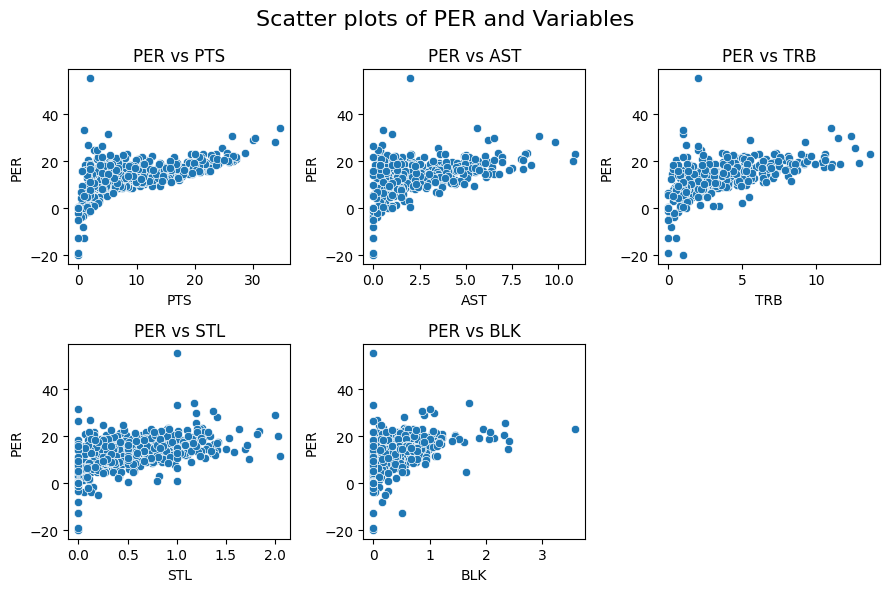

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 서브플롯 설정 (2행 3열)
fig, axs = plt.subplots(2, 3, figsize=(9, 6))
fig.suptitle('Scatter plots of PER and Variables', fontsize=16)

# 평평하게 만든 axs 배열
axs = axs.ravel()

# 변수 리스트 (A를 제외한 나머지 변수들)
x_vars = ['PTS', 'AST', 'TRB', 'STL', 'BLK']

# 각 변수에 대한 산점도 그리기
for i, x_var in enumerate(x_vars):
    sns.scatterplot(data=df_stats_per, x=x_var, y='PER', ax=axs[i])
    axs[i].set_title(f'PER vs {x_var}')

# 마지막 서브플롯 제거 (변수가 5개이므로)
fig.delaxes(axs[5])

# 레이아웃 조정
plt.tight_layout()
plt.show()

In [17]:
df_stats_per = df_stats_per.iloc[:100]

In [19]:
df_stats_per.head()

,PER,PTS,AST,TRB,STL,BLK
0,28.1,33.857143,9.800000,9.242857,1.414286,0.542857
1,29.3,30.053333,6.200000,5.533333,2.000000,0.893333
2,29.9,30.438356,6.520548,11.520548,1.191781,1.082192
3,23.4,28.727273,6.740260,3.610390,0.909091,0.168831
4,31.0,26.392405,8.962025,12.354430,1.367089,0.860759


In [21]:
df_stats_per_50 = df_stats_per.iloc[:50]

In [23]:
import pandas as pd

# Excel 파일로 저장
file_name = "NBA 회귀분석 데이터.xlsx"
df_stats_per_50.to_excel(file_name, index=False)  # index=False로 설정하여 인덱스 제거

# Google Colab에서 다운로드
from google.colab import files
files.download(file_name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# 독립변수 (X)와 종속변수 (y) 정의
X = df_stats_per[['PTS', 'AST', 'TRB', 'STL', 'BLK']]
y = df_stats_per['PER']

# 절편 추가
X = sm.add_constant(X)

# OLS 모델 생성 및 적합
ols_model = sm.OLS(y, X).fit()

# 잔차 추출
residuals = ols_model.resid

# Breusch-Pagan Test 수행
bp_test = het_breuschpagan(residuals, X)

# 결과 출력 (검정 통계량, p-value, F-stat, F p-value)
print(f"BP Test Statistic: {bp_test[0]}")
print(f"BP Test p-value: {bp_test[1]}")

# p-value < 0.05이면 등분산성이 깨진 것 (이분산성 존재)
if bp_test[1] < 0.05:
    print("⚠️ 이분산성이 존재합니다! GLS 모델을 고려하세요.")
else:
    print("✅ 등분산성이 유지됩니다. OLS를 그대로 사용해도 됩니다.")


BP Test Statistic: 17.58384637354211
BP Test p-value: 0.0035158293268325092
⚠️ 이분산성이 존재합니다! GLS 모델을 고려하세요.


In [15]:
# GLS 회귀 분석
gls_model = sm.GLS(y, X).fit()

# 결과 출력
print(gls_model.summary())


                            GLS Regression Results                            
Dep. Variable:                    PER   R-squared:                       0.384
Model:                            GLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     70.57
Date:                Sat, 29 Mar 2025   Prob (F-statistic):           2.42e-57
Time:                        12:36:36   Log-Likelihood:                -1732.5
No. Observations:                 572   AIC:                             3477.
Df Residuals:                     566   BIC:                             3503.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9198      0.409     16.939      0.0